# Coin Classification via Blurred Polar Matching

This notebook implements a noise-robust classification pipeline by applying Gaussian blur to edge maps and using high-resolution weighted polar matrices.

## Phase 1: Loading Reference Edge Maps
Scanning the `ROI_REF_EDGES` folder for pre-normalized (250x250) edge images.

In [25]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import os

# Global Parameters
CANVAS_SIZE = 250
CENTER = (125, 125)
MAX_RADIUS = 100
POLAR_DIMS = (360, 50)  # Reverting to 360 degrees x 50 radial bins

print("--- PHASE 1: Loading Reference ROIs ---")
ref_edges_dir = Path('ROI_REF_EDGES')
reference_polar_library = {}

if not ref_edges_dir.exists():
    print(f"ERROR: Folder {ref_edges_dir} does not exist.")
else:
    for img_path in sorted(ref_edges_dir.glob('*')):
        if img_path.suffix.lower() in ('.jpg', '.png', '.jpeg'):
            # Load binary edge map (already normalized 250x250)
            edge_map = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)
            if edge_map is not None:
                # Apply light Gaussian Blur to soften the edges
                blurred_ref = cv2.GaussianBlur(edge_map, (5, 5), 0)
                reference_polar_library[img_path.name] = blurred_ref
                print(f"Mapped and blurred reference: {img_path.name}")

print(f"\nTotal reference coins loaded: {len(reference_polar_library)}")

--- PHASE 1: Loading Reference ROIs ---
Mapped and blurred reference: 10cent.jpg
Mapped and blurred reference: 1cent.jpg
Mapped and blurred reference: 1euro.jpg
Mapped and blurred reference: 20cent.jpg
Mapped and blurred reference: 2cent.jpg
Mapped and blurred reference: 2euro.jpg
Mapped and blurred reference: 50cent.jpg
Mapped and blurred reference: 5cent.jpg

Total reference coins loaded: 8


## Phase 2: Target Image Pre-processing
Extracting a normalized 250x250 edge ROI from the target image.

--- PHASE 2: Target ROI Pre-processing ---


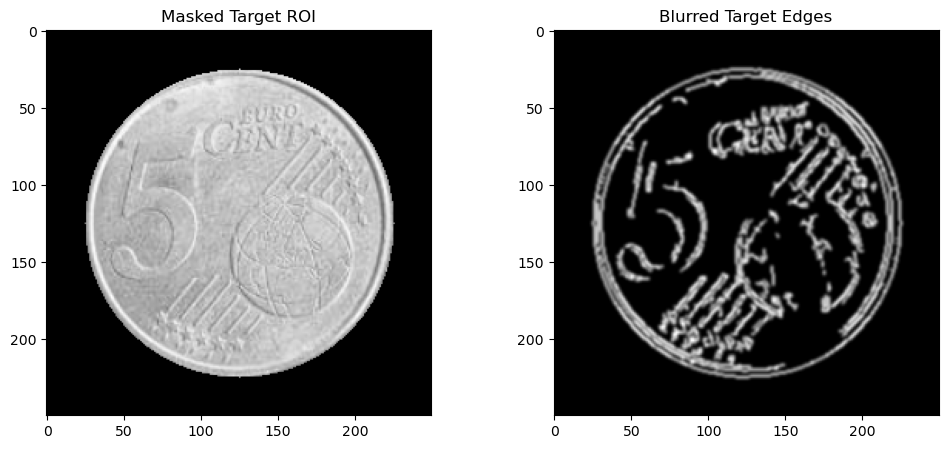

In [26]:
print("--- PHASE 2: Target ROI Pre-processing ---")

target_path = Path('test/5_cent_wild.jpg')
#target_path = Path('test/50_cent_wild.png')
#target_path = Path('test/20_cent_wild.jpg')
#target_path = Path('test/2_eur_left.jpg')
#target_path = Path('test/10_cent_wild.jpg')

# Load original image
target_img = cv2.imread(str(target_path))
if target_img is None:
    print(f"ERROR: Target image not found at {target_path}")
else:
    target_gray = cv2.cvtColor(target_img, cv2.COLOR_BGR2GRAY)
    blur = cv2.medianBlur(target_gray, 7)

    # Locate coin for normalization (Hough Circles)
    circles = cv2.HoughCircles(
        blur, cv2.HOUGH_GRADIENT, dp=1.2, minDist=100,
        param1=100, param2=30, minRadius=50, maxRadius=150
    )

    if circles is not None:
        circles = np.uint16(np.around(circles))
        x, y, r = circles[0][0]
        
        # Affine Transform to force 250x250 ROI with normalized radius
        TARGET_NORM_RADIUS = 100 
        scale = TARGET_NORM_RADIUS / r
        M = np.float32([
            [scale, 0, CENTER[0] - x * scale],
            [0, scale, CENTER[1] - y * scale]
        ])
        target_roi = cv2.warpAffine(target_gray, M, (CANVAS_SIZE, CANVAS_SIZE))
        
        # Mask the ROI before edge extraction to avoid background edges
        mask = np.zeros((CANVAS_SIZE, CANVAS_SIZE), dtype=np.uint8)
        cv2.circle(mask, CENTER, TARGET_NORM_RADIUS, 255, -1)
        masked_target_roi = cv2.bitwise_and(target_roi, mask)
        
        # Extract binary edges (Canny) from the MASKED ROI
        target_edges = cv2.Canny(masked_target_roi, 100, 200)
        
        # Apply light Gaussian Blur to soften the target edges
        blurred_target_edges = cv2.GaussianBlur(target_edges, (5, 5), 0)
        
        # Visualization
        fig, ax = plt.subplots(1, 2, figsize=(12, 5))
        ax[0].imshow(masked_target_roi, cmap='gray')
        ax[0].set_title("Masked Target ROI")
        ax[1].imshow(blurred_target_edges, cmap='gray')
        ax[1].set_title("Blurred Target Edges")
        plt.show()
    else:
        print("ERROR: No coin detected in target image.")

## Phase 3: Building Weighted Polar Matrices
Transforming blurred edge maps into 360x50 matrices using intensity weights.

--- PHASE 3: Generating Weighted Polar Matrices ---


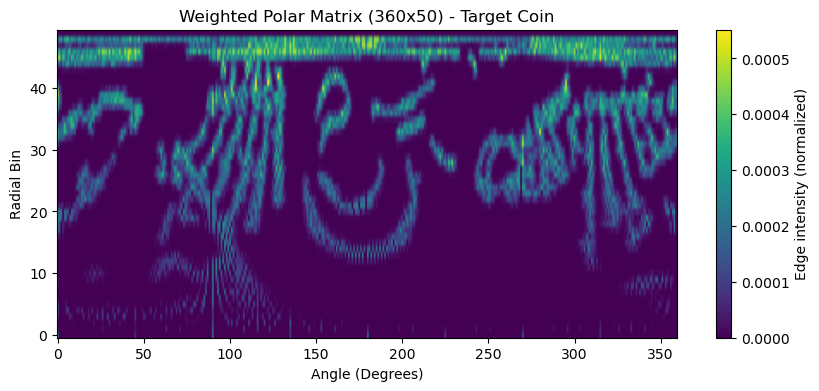

In [27]:
def build_weighted_polar_matrix(blurred_img, center=CENTER, max_r=MAX_RADIUS, dims=POLAR_DIMS):
    """Transforms a blurred edge map into a weighted polar matrix."""
    ang_bins, rad_bins = dims
    polar_matrix = np.zeros(dims, dtype=np.float32)
    
    # Get coordinates and intensities of all pixels with value > 0
    y_coords, x_coords = np.where(blurred_img > 0)
    intensities = blurred_img[y_coords, x_coords]
    
    # Transform to polar relative to center
    dx = x_coords - center[0]
    dy = y_coords - center[1]
    
    r = np.sqrt(dx**2 + dy**2)
    theta = (np.degrees(np.arctan2(dy, dx)) + 360) % 360
    
    # Filter and Binning
    valid_mask = r < max_r
    r_idx = ((r[valid_mask] / max_r) * (rad_bins - 1)).astype(int)
    theta_idx = ((theta[valid_mask] / 360) * (ang_bins)).astype(int) % ang_bins
    weights = intensities[valid_mask]
    
    # Use np.add.at for efficient weighted accumulation
    np.add.at(polar_matrix, (theta_idx, r_idx), weights)
        
    # Normalize by total intensity to get a relative distribution
    total = np.sum(polar_matrix)
    if total > 0: polar_matrix /= total
        
    return polar_matrix

print("--- PHASE 3: Generating Weighted Polar Matrices ---")
reference_polar_mats = {name: build_weighted_polar_matrix(img) for name, img in reference_polar_library.items()}
target_polar_mat = build_weighted_polar_matrix(blurred_target_edges)


# Visualization of Target Polar Matrix
plt.figure(figsize=(10, 4))
plt.imshow(target_polar_mat.T, aspect='auto', cmap='viridis', origin='lower')
plt.colorbar(label='Edge intensity (normalized)')
plt.title(f"Weighted Polar Matrix ({POLAR_DIMS[0]}x{POLAR_DIMS[1]}) - Target Coin")
plt.xlabel("Angle (Degrees)")
plt.ylabel("Radial Bin")
plt.show()

## Phase 4: Rotational Matching
Comparing matrices using asymmetric intersection over 360 degrees.

In [28]:
def match_polar_matrices(ref_mat, target_mat):
    """Performs rotational matching on high-res polar matrices."""
    best_score = -1.0
    best_angle = 0
    
    num_steps = ref_mat.shape[0]
    
    for step in range(num_steps):
        # Circular shift on Angular axis
        rotated_tgt = np.roll(target_mat, shift=step, axis=0)
        
        # Intersection score
        score = np.sum(np.minimum(ref_mat, rotated_tgt))
        
        if score > best_score:
            best_score = score
            best_angle = step
            
    return best_score, best_angle

print("--- PHASE 4: Matching Processing ---")

--- PHASE 4: Matching Processing ---


## Phase 5: Final Classification and Results
Evaluating the target against all references and identifying the winner.

In [29]:
print("--- PHASE 5: Classification Results ---")
results = []

for name, ref_mat in reference_polar_mats.items():
    score, angle = match_polar_matrices(ref_mat, target_polar_mat)
    results.append((name, score, angle))

# Sort by score descending
results.sort(key=lambda x: x[1], reverse=True)

print(f"{'REFERENCE':<20} | {'SCORE':<10} | {'BEST ANGLE':<10}")
print("-" * 45)
for name, score, angle in results:
    print(f"{name:<20} | {score:10.4f} | {angle:7}°")

if results:
    winner_name, winner_score, _ = results[0]
    print("\n" + "="*40)
    print(f" FINAL VERDICT: {winner_name.upper()}")
    print(f" CONFIDENCE: {winner_score:.4f}")
    print("="*40)
else:
    print("No classification results found.")

--- PHASE 5: Classification Results ---
REFERENCE            | SCORE      | BEST ANGLE
---------------------------------------------
5cent.jpg            |     0.4878 |     325°
1cent.jpg            |     0.4834 |       0°
10cent.jpg           |     0.4801 |      90°
20cent.jpg           |     0.4644 |      90°
50cent.jpg           |     0.4472 |     270°
2cent.jpg            |     0.4472 |     309°
1euro.jpg            |     0.4438 |     270°
2euro.jpg            |     0.4242 |     270°

 FINAL VERDICT: 5CENT.JPG
 CONFIDENCE: 0.4878


## Phase 6: Visual Comparison of Rankings
Visualizing the target polar matrix alongside all reference matrices, sorted by score.

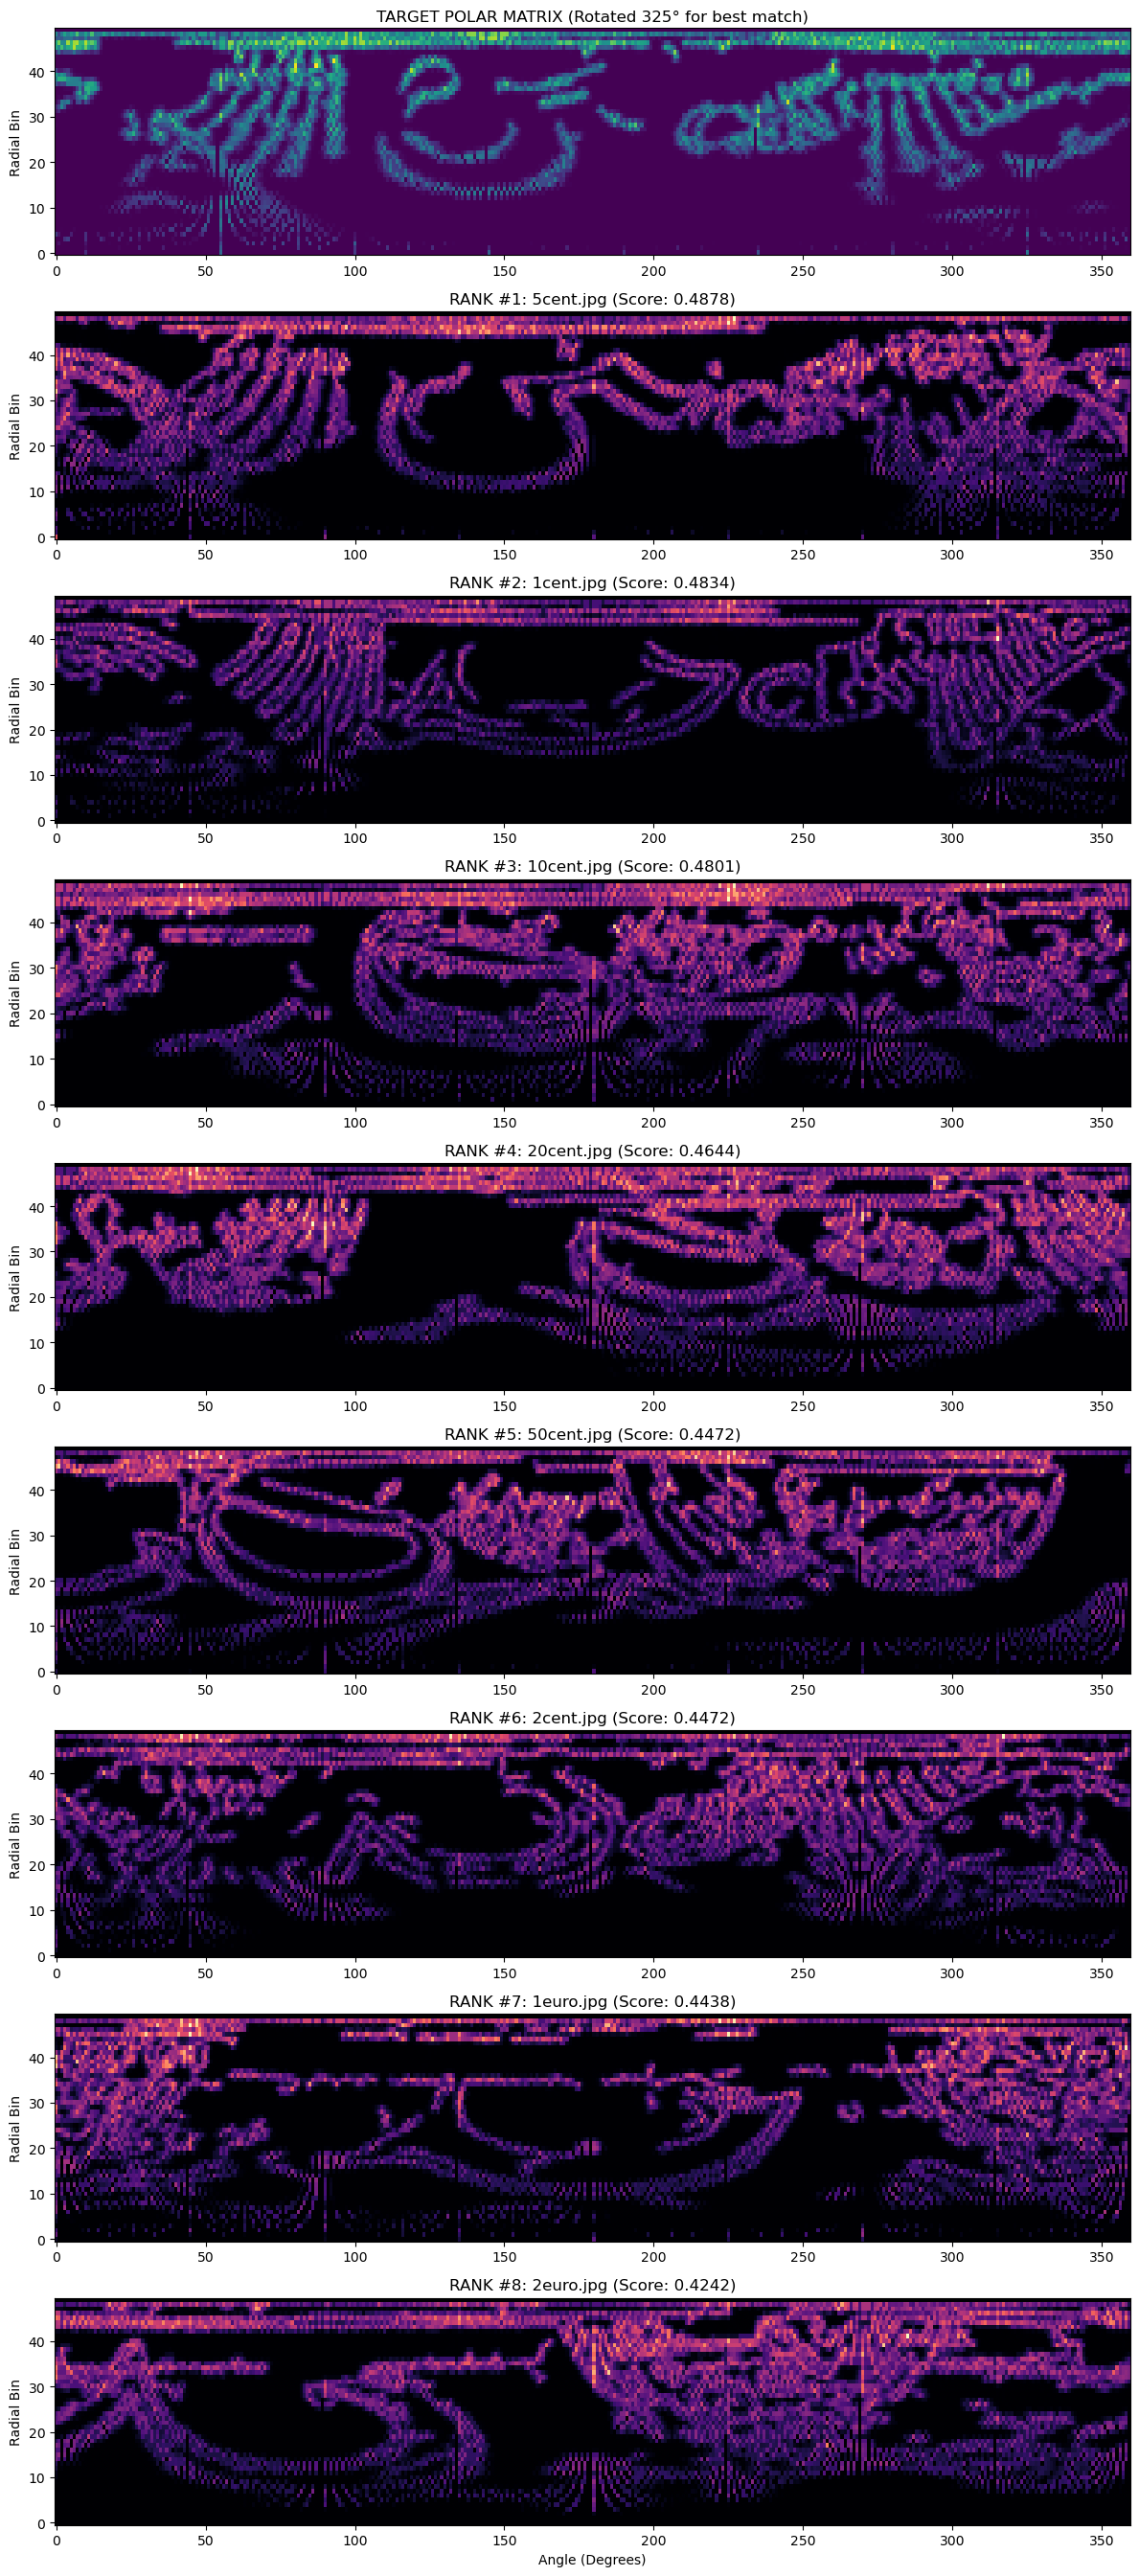

In [30]:
if results:
    fig, axes = plt.subplots(len(results) + 1, 1, figsize=(12, 3 * (len(results) + 1)))
    
    # 1. Rotated Target Polar Matrix (using best angle from top match)
    best_angle = results[0][2]
    rotated_target = np.roll(target_polar_mat, shift=best_angle, axis=0)
    
    axes[0].imshow(rotated_target.T, aspect='auto', cmap='viridis', origin='lower')
    axes[0].set_title(f"TARGET POLAR MATRIX (Rotated {best_angle}° for best match)")
    axes[0].set_ylabel("Radial Bin")

    # 2. All Reference Polar Matrices in order
    for i, (name, score, angle) in enumerate(results):
        ref_mat = reference_polar_mats[name]
        axes[i+1].imshow(ref_mat.T, aspect='auto', cmap='magma', origin='lower')
        axes[i+1].set_title(f"RANK #{i+1}: {name} (Score: {score:.4f})")
        axes[i+1].set_ylabel("Radial Bin")
        
    plt.xlabel("Angle (Degrees)")
    plt.tight_layout()
    plt.show()
else:
    print("Nothing to visualize.")